# Flood Guard - Análise de alagamentos e inundações na cidade de São Paulo

**Turma:** 1TSCOB  
**Grupo:** Core III   
**Integrantes:** Henrique Montanhas - RM572145; Leonardo Reis - RM569218; Victoria Duarte - RM573688

## Problema e hipóteses

Alagamentos e inundações interrompem deslocamentos e expõem moradores a riscos. O projeto **Flood Guard** propõe alertas por região, indicação de rotas a evitar e orientações acessíveis mesmo em conexões limitadas.

Esta análise responde às seguintes perguntas:

1. As ocorrências se concentram no período mais chuvoso, entre novembro e março?
2. Algumas subprefeituras concentram parcela relevante dos registros?
3. Os pontos formam agrupamentos geográficos que podem orientar alertas regionalizados?

**Hipóteses:** H1 - existe sazonalidade; H2 - existe concentração territorial; H3 - agrupamentos espaciais permitem dividir a cidade em núcleos operacionais de alerta.

## Fontes e recorte

- **Fonte primária:** Prefeitura de São Paulo, Defesa Civil e GeoSampa. A camada oficial informa ocorrências de alagamentos e inundações e mantém a série histórica desde 2013.  
  Metadados: https://metadados.geosampa.prefeitura.sp.gov.br/geonetwork/srv/api/records/432c06b1-03a1-4b1f-9210-423e1b58e869
- **Arquivo utilizado:** consolidação pública da série histórica do GeoSampa em CSV, com coordenadas UTM, data, tipo de ocorrência e subprefeitura.  
  Repositório: https://github.com/23216886alunivesp/sp-alagamentos-inundacoes-defesa-civil
- **Período do arquivo:** 2013 a 2026. Para comparações, usamos **2020 a 2025**, os seis anos completos mais recentes. Os registros de 2026 ficam fora das comparações anuais por representarem um ano incompleto.

### Variáveis utilizadas

| Variável | Descrição |
|---|---|
| `X`, `Y` | Coordenadas no sistema SIRGAS 2000 / UTM 23S |
| `data` | Data da ocorrência |
| `ocorrencia` | Alagamento ou inundação |
| `subprefeit` | Subprefeitura registrada na fonte |
| `name` | Identificador do registro na fonte |

In [1]:
from pathlib import Path
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chisquare
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

os.environ["LOKY_MAX_CPU_COUNT"] = "2"
warnings.filterwarnings("ignore", category=FutureWarning)

plt.style.use("seaborn-v0_8-whitegrid")
CORES = {"ALAGAMENTO": "#14B8A6", "INUNDACAO": "#E74667"}

ARQUIVO = Path("dados/ocorrencias_alagamentos_inundacoes_sp_2013_2026.csv")
assert ARQUIVO.exists(), f"Arquivo não encontrado: {ARQUIVO}"

Matplotlib is building the font cache; this may take a moment.


## 1. Carregamento e diagnóstico inicial

In [2]:
df_bruto = pd.read_csv(ARQUIVO)

print(f"Dimensão inicial: {df_bruto.shape[0]:,} linhas e {df_bruto.shape[1]} colunas".replace(",", "."))
print("\nTipos originais:")
print(df_bruto.dtypes)
print("\nValores ausentes:")
print(df_bruto.isna().sum())
print(f"\nDuplicatas exatas: {df_bruto.duplicated().sum()}")
df_bruto.head()

Dimensão inicial: 12.487 linhas e 6 colunas

Tipos originais:
X             float64
Y             float64
data              str
ocorrencia        str
subprefeit        str
name          float64
dtype: object

Valores ausentes:
X               0
Y               0
data            0
ocorrencia      0
subprefeit      0
name          589
dtype: int64

Duplicatas exatas: 113


,X,Y,data,ocorrencia,subprefeit,name
0,325784.879025,7.383070e+06,2013/12/10,ALAGAMENTO,SA - SANTO AMARO,45361.0
1,332700.974737,7.394729e+06,2013/12/25,ALAGAMENTO,SE - SE,46709.0
2,349044.816165,7.401931e+06,2013/12/26,INUNDACAO,EM - ERMELINO MATARAZZO,46740.0
3,349027.882703,7.401919e+06,2013/12/26,INUNDACAO,EM - ERMELINO MATARAZZO,46737.0
4,349027.882703,7.401919e+06,2013/12/26,INUNDACAO,EM - ERMELINO MATARAZZO,46738.0


O identificador `name` possui ausências, mas não é necessário para as análises. Data, coordenadas, tipo e subprefeitura estão preenchidos no arquivo bruto. As duplicatas exatas serão removidas para evitar dupla contagem.

## 2. Limpeza, normalização e seleção do período

In [3]:
df = df_bruto.copy()
df.columns = [c.strip().lower() for c in df.columns]

# A fonte combina datas com barras e hífens. O formato misto trata os dois padrões.
df["data"] = pd.to_datetime(df["data"], format="mixed", errors="coerce")
df["ocorrencia"] = df["ocorrencia"].astype("string").str.strip().str.upper()
df["subprefeit"] = df["subprefeit"].astype("string").str.strip()

linhas_iniciais = len(df)
duplicatas = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

# Mantemos somente registros com os campos indispensáveis válidos.
df = df.dropna(subset=["data", "x", "y", "ocorrencia"])
df = df[df["ocorrencia"].isin(["ALAGAMENTO", "INUNDACAO"])].copy()

mapa_subprefeituras = {
    "AD": "Cidade Ademar", "AF": "Aricanduva/Formosa/Carrão", "BT": "Butantã",
    "CL": "Campo Limpo", "CS": "Capela do Socorro", "CT": "Cidade Tiradentes",
    "CV": "Casa Verde/Cachoeirinha", "EM": "Ermelino Matarazzo",
    "FO": "Freguesia/Brasilândia", "GU": "Guaianases", "IP": "Ipiranga",
    "IQ": "Itaquera", "IT": "Itaim Paulista", "JA": "Jabaquara",
    "JT": "Jaçanã/Tremembé", "LA": "Lapa", "MB": "M'Boi Mirim",
    "MG": "Vila Maria/Vila Guilherme", "MO": "Mooca", "MP": "São Miguel Paulista",
    "PA": "Parelheiros", "PE": "Penha", "PI": "Pinheiros",
    "PJ": "Pirituba/Jaraguá", "PR": "Perus", "SA": "Santo Amaro",
    "SB": "Sapopemba", "SE": "Sé", "SM": "São Mateus",
    "ST": "Santana/Tucuruvi", "VM": "Vila Mariana", "VP": "Vila Prudente"
}

# A base contém grafias diferentes para a mesma subprefeitura. O código é mais estável.
codigo = (
    df["subprefeit"].str.upper().str.strip()
      .str.extract(r"^([A-Z]+)", expand=False)
      .replace({"G": "GU"})
)
df["subprefeitura"] = codigo.map(mapa_subprefeituras)

df["ano"] = df["data"].dt.year
df["mes"] = df["data"].dt.month
df["periodo_chuvoso"] = df["mes"].isin([11, 12, 1, 2, 3])

# Seis anos completos mais recentes.
analise = df[df["ano"].between(2020, 2025)].copy()
geo = analise.dropna(subset=["subprefeitura"]).copy()

print(f"Linhas iniciais: {linhas_iniciais:,}".replace(",", "."))
print(f"Duplicatas removidas: {duplicatas}")
print(f"Linhas válidas após limpeza: {len(df):,}".replace(",", "."))
print(f"Registros no recorte 2020-2025: {len(analise):,}".replace(",", "."))
print(f"Registros com subprefeitura normalizada: {len(geo):,}".replace(",", "."))
print(f"Período analisado: {analise['data'].min().date()} a {analise['data'].max().date()}")

Linhas iniciais: 12.487
Duplicatas removidas: 113
Linhas válidas após limpeza: 12.374
Registros no recorte 2020-2025: 3.189
Registros com subprefeitura normalizada: 3.188
Período analisado: 2020-01-01 a 2025-12-31


### Tratamento de outliers

Ocorrências extremas em um mesmo dia podem representar eventos reais intensos. Por isso, elas foram identificadas, mas não removidas automaticamente. Excluir esses dias reduziria justamente a evidência do problema que a solução pretende enfrentar.

In [4]:
calendario = pd.date_range("2020-01-01", "2025-12-31", freq="D")
ocorrencias_dia = analise.groupby("data").size().reindex(calendario, fill_value=0)
q1, q3 = ocorrencias_dia.quantile([0.25, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

print(f"Média diária incluindo dias sem ocorrência: {ocorrencias_dia.mean():.2f}")
print(f"Mediana diária: {ocorrencias_dia.median():.2f}")
print(f"Desvio-padrão diário: {ocorrencias_dia.std():.2f}")
print(f"Limite de outlier pelo IQR: {limite_superior:.2f}")
print("\nCinco dias com mais registros:")
print(ocorrencias_dia.nlargest(5))

Média diária incluindo dias sem ocorrência: 1.45
Mediana diária: 0.00
Desvio-padrão diário: 6.90
Limite de outlier pelo IQR: 2.50

Cinco dias com mais registros:
2020-02-10    215
2025-02-01    136
2025-02-03     60
2023-01-30     56
2025-01-24     52
dtype: int64


## 3. Estatística descritiva e evolução anual

Ocorrências por tipo:
ocorrencia
INUNDACAO     1670
ALAGAMENTO    1519
Name: count, dtype: Int64

Ocorrências por ano:
ocorrencia  ALAGAMENTO  INUNDACAO  TOTAL
ano                                     
2020               326        306    632
2021               155         96    251
2022               220        170    390
2023               323        480    803
2024               214        237    451
2025               281        381    662


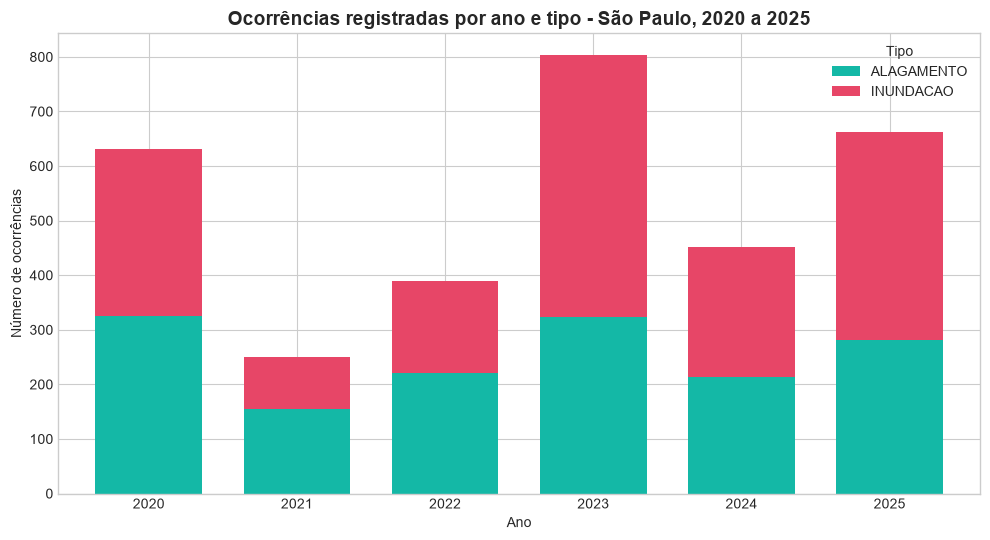

In [6]:
resumo_tipos = analise["ocorrencia"].value_counts()
resumo_anos = analise.groupby(["ano", "ocorrencia"]).size().unstack(fill_value=0)

print("Ocorrências por tipo:")
print(resumo_tipos)
print("\nOcorrências por ano:")
print(resumo_anos.assign(TOTAL=resumo_anos.sum(axis=1)))

ax = resumo_anos[["ALAGAMENTO", "INUNDACAO"]].plot(
    kind="bar", stacked=True, figsize=(10, 5.5),
    color=[CORES["ALAGAMENTO"], CORES["INUNDACAO"]], width=0.72
)
ax.set_title("Ocorrências registradas por ano e tipo - São Paulo, 2020 a 2025", fontsize=14, weight="bold")
ax.set_xlabel("Ano")
ax.set_ylabel("Número de ocorrências")
ax.legend(title="Tipo")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()

from pathlib import Path
Path("graficos").mkdir(parents=True, exist_ok=True)

plt.savefig("graficos/01_evolucao_anual.png", dpi=180, bbox_inches="tight")
plt.show()

**Interpretação:** o volume anual oscila bastante. O pico do recorte ocorreu em 2023, com 803 registros, enquanto 2021 apresentou 251. Essa variabilidade reforça a necessidade de monitoramento contínuo, mas não permite concluir que exista uma tendência linear de aumento.

## 4. Distribuição mensal e probabilidade

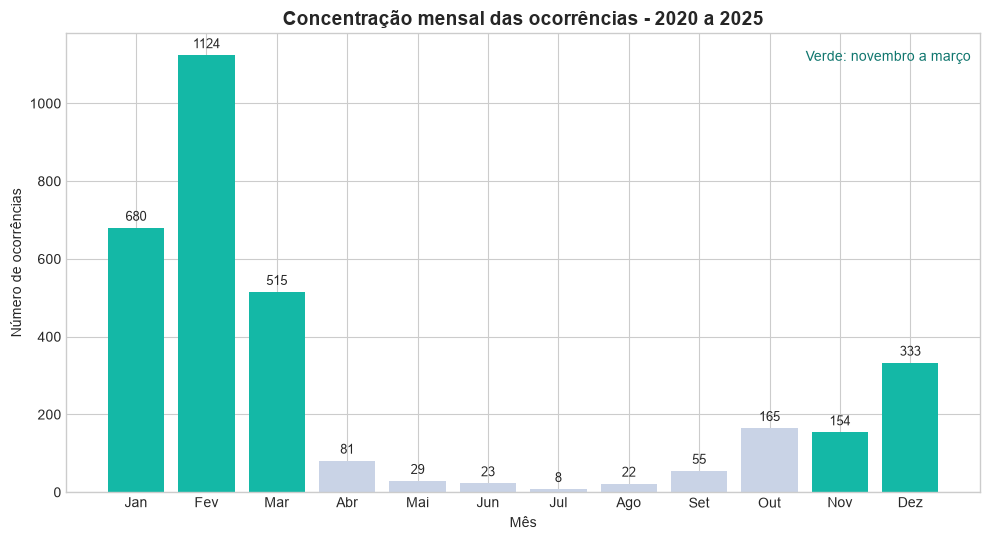

In [7]:
nomes_meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
mensal = analise.groupby("mes").size().reindex(range(1, 13), fill_value=0)
cores_meses = ["#14B8A6" if m in [11, 12, 1, 2, 3] else "#C9D3E6" for m in range(1, 13)]

fig, ax = plt.subplots(figsize=(10, 5.5))
barras = ax.bar(nomes_meses, mensal.values, color=cores_meses)
ax.set_title("Concentração mensal das ocorrências - 2020 a 2025", fontsize=14, weight="bold")
ax.set_xlabel("Mês")
ax.set_ylabel("Número de ocorrências")
for barra, valor in zip(barras, mensal.values):
    ax.text(barra.get_x() + barra.get_width()/2, valor + 18, str(valor), ha="center", fontsize=9)
ax.text(0.99, 0.94, "Verde: novembro a março", transform=ax.transAxes, ha="right", color="#0F766E")
plt.tight_layout()
plt.savefig("graficos/02_distribuicao_mensal.png", dpi=180, bbox_inches="tight")
plt.show()

In [8]:
n = len(analise)
n_chuvoso = int(analise["periodo_chuvoso"].sum())
p_chuvoso = n_chuvoso / n
erro_padrao = np.sqrt(p_chuvoso * (1 - p_chuvoso) / n)
ic_inferior, ic_superior = p_chuvoso - 1.96 * erro_padrao, p_chuvoso + 1.96 * erro_padrao

print(f"Registros entre novembro e março: {n_chuvoso:,} de {n:,}".replace(",", "."))
print(f"Probabilidade estimada: {p_chuvoso:.1%}")
print(f"Intervalo de confiança aproximado de 95%: {ic_inferior:.1%} a {ic_superior:.1%}")

Registros entre novembro e março: 2.806 de 3.189
Probabilidade estimada: 88.0%
Intervalo de confiança aproximado de 95%: 86.9% a 89.1%


**Técnica escolhida - probabilidade:** usamos a frequência relativa para estimar a chance de um registro histórico ocorrer entre novembro e março. O resultado de 88,0% mostra forte concentração no período mais chuvoso. Essa é uma probabilidade histórica, não a previsão de um dia específico.

## 5. Teste de hipótese sobre sazonalidade

In [9]:
# H0: a distribuição acompanha apenas a quantidade de dias de cada mês.
# H1: a distribuição mensal é diferente do esperado sem sazonalidade.
dias = pd.Series(pd.date_range("2020-01-01", "2025-12-31", freq="D").month).value_counts().sort_index()
esperado = mensal.sum() * dias.values / dias.sum()
qui2, p_valor = chisquare(f_obs=mensal.values, f_exp=esperado)

print(f"Estatística qui-quadrado: {qui2:.2f}")
print("p-valor: < 0,001" if p_valor < 0.001 else f"p-valor: {p_valor:.4f}")
print("Decisão: rejeitar H0; há evidência estatística de sazonalidade." if p_valor < 0.05 else "Decisão: não rejeitar H0.")

Estatística qui-quadrado: 5252.88
p-valor: < 0,001
Decisão: rejeitar H0; há evidência estatística de sazonalidade.


**Técnica escolhida - teste de hipótese:** o teste qui-quadrado compara a quantidade observada em cada mês com a quantidade esperada proporcionalmente ao número de dias. O resultado é estatisticamente significativo (`p < 0,001`), sustentando H1. O teste identifica associação temporal, mas não prova que a chuva tenha causado cada registro individual.

## 6. Concentração por subprefeitura

Dez subprefeituras com mais registros:
subprefeitura
São Miguel Paulista      727
Campo Limpo              191
Itaquera                 175
M'Boi Mirim              154
Pirituba/Jaraguá         129
Capela do Socorro        122
Butantã                  120
Penha                    107
São Mateus               106
Freguesia/Brasilândia    105
Name: count, dtype: int64

Participação das cinco primeiras: 43.2%


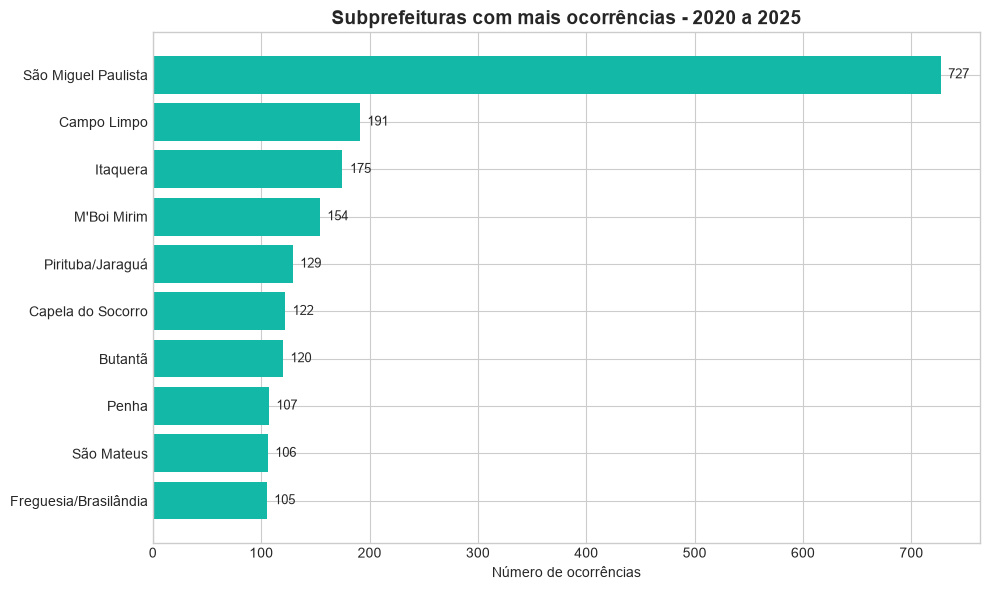

In [10]:
ranking = geo["subprefeitura"].value_counts()
top10 = ranking.head(10).sort_values()
participacao_top5 = ranking.head(5).sum() / ranking.sum()

print("Dez subprefeituras com mais registros:")
print(ranking.head(10))
print(f"\nParticipação das cinco primeiras: {participacao_top5:.1%}")

fig, ax = plt.subplots(figsize=(10, 6))
barras = ax.barh(top10.index, top10.values, color="#14B8A6")
ax.set_title("Subprefeituras com mais ocorrências - 2020 a 2025", fontsize=14, weight="bold")
ax.set_xlabel("Número de ocorrências")
ax.set_ylabel("")
for barra, valor in zip(barras, top10.values):
    ax.text(valor + 7, barra.get_y() + barra.get_height()/2, str(valor), va="center", fontsize=9)
plt.tight_layout()
plt.savefig("graficos/03_ranking_subprefeituras.png", dpi=180, bbox_inches="tight")
plt.show()

**Interpretação:** após padronizar grafias diferentes, São Miguel Paulista aparece com 727 registros. As cinco primeiras subprefeituras concentram 43,2% dos registros geograficamente identificados. Isso sustenta H2, mas o resultado também pode refletir diferenças na cobertura e no processo de registro.

## 7. Agrupamento geográfico com Machine Learning

In [11]:
# K-Means foi escolhido para resumir milhares de pontos em núcleos operacionais.
coordenadas = geo[["x", "y"]].to_numpy()
escala = StandardScaler()
coordenadas_padronizadas = escala.fit_transform(coordenadas)

modelo = KMeans(n_clusters=5, random_state=42, n_init=20)
geo["cluster"] = modelo.fit_predict(coordenadas_padronizadas) + 1

resumo_clusters = []
for cluster, grupo in geo.groupby("cluster"):
    resumo_clusters.append({
        "cluster": cluster,
        "registros": len(grupo),
        "subprefeitura_dominante": grupo["subprefeitura"].mode().iloc[0],
        "x_centro": grupo["x"].mean(),
        "y_centro": grupo["y"].mean(),
    })
resumo_clusters = pd.DataFrame(resumo_clusters).sort_values("cluster")
resumo_clusters

,cluster,registros,subprefeitura_dominante,x_centro,y_centro
0,1,503,São Mateus,348305.256451,7.391488e+06
1,2,190,Capela do Socorro,326556.374134,7.370266e+06
2,3,700,Pirituba/Jaraguá,328419.227204,7.401685e+06
3,4,697,Campo Limpo,324152.074252,7.384179e+06
4,5,1098,São Miguel Paulista,353670.013427,7.400621e+06


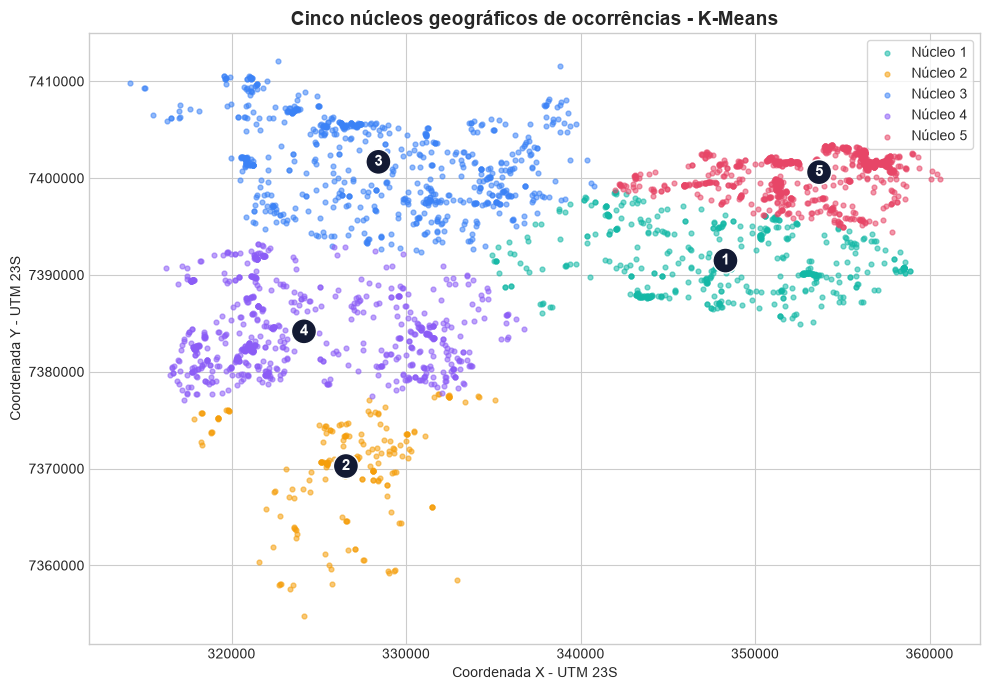

In [12]:
fig, ax = plt.subplots(figsize=(10, 7))
paleta = ["#14B8A6", "#F59E0B", "#3B82F6", "#8B5CF6", "#E74667"]
for cluster, grupo in geo.groupby("cluster"):
    ax.scatter(grupo["x"], grupo["y"], s=12, alpha=0.55, color=paleta[cluster-1], label=f"Núcleo {cluster}")

for _, linha in resumo_clusters.iterrows():
    ax.text(linha["x_centro"], linha["y_centro"], str(int(linha["cluster"])),
            ha="center", va="center", fontsize=11, weight="bold", color="white",
            bbox=dict(boxstyle="circle,pad=0.35", facecolor="#131A33", edgecolor="white"))

ax.set_title("Cinco núcleos geográficos de ocorrências - K-Means", fontsize=14, weight="bold")
ax.set_xlabel("Coordenada X - UTM 23S")
ax.set_ylabel("Coordenada Y - UTM 23S")
ax.legend(loc="best", frameon=True)
ax.ticklabel_format(style="plain", axis="both")
plt.tight_layout()
plt.savefig("graficos/04_clusters_geograficos.png", dpi=180, bbox_inches="tight")
plt.show()

**Técnica escolhida - K-Means:** o agrupamento reduz os pontos a cinco núcleos territoriais. O maior núcleo reúne 1.098 registros e tem São Miguel Paulista como subprefeitura dominante. Os grupos não substituem a avaliação da Defesa Civil, mas podem orientar regiões iniciais para alertas, painéis e validação de campo. Assim, H3 foi sustentada como estratégia operacional exploratória.

## 8. Conclusões e conexão com o Flood Guard

### Hipóteses

- **H1 sustentada:** 88,0% dos registros ocorreram entre novembro e março, com `p < 0,001` no teste de sazonalidade.
- **H2 sustentada:** cinco subprefeituras concentram 43,2% dos registros geograficamente identificados.
- **H3 sustentada de forma exploratória:** o K-Means organizou os pontos em cinco núcleos, permitindo priorização regional. Os núcleos ainda exigem validação com especialistas e moradores.

### Como os resultados orientam a solução

1. O sistema deve intensificar o monitoramento e a comunicação antes e durante o período mais chuvoso.
2. A primeira implantação pode priorizar São Miguel Paulista e outros territórios do ranking, sem excluir o restante da cidade.
3. Alertas devem usar localização aproximada e nível de risco, evitando coleta desnecessária de dados pessoais.
4. O painel de gestão pode acompanhar ocorrências por mês, subprefeitura e núcleo geográfico.

### Indicadores propostos

- percentual de alertas enviados antes do evento;
- tempo entre detecção de risco e aviso ao cidadão;
- usuários alcançados por região;
- redução de deslocamentos por vias sinalizadas como críticas;
- taxa de alertas confirmados por dados oficiais.

## 9. Limitações, vieses e uso responsável

- Os registros representam ocorrências atendidas ou cadastradas. Eles não capturam todos os eventos que aconteceram na cidade.
- A cobertura pode variar por período e território. Regiões com maior acesso aos canais de atendimento podem aparecer mais na base.
- Mudanças operacionais na forma de registrar ocorrências dificultam comparações causais entre anos.
- A análise não integrou precipitação diária. Portanto, sazonalidade não deve ser interpretada como prova causal para cada ocorrência.
- O K-Means cria divisões matemáticas e pode simplificar excessivamente fronteiras urbanas e características locais.
- Para respeitar a LGPD, a solução deve trabalhar com localização aproximada, consentimento explícito, retenção mínima, criptografia e controle de acesso. Dados para análise pública devem ser agregados e anonimizados.
- Pessoas sem smartphone ou conexão devem receber alertas também por SMS, WhatsApp leve, painéis comunitários e apoio de associações locais.

## ODS relacionados

- **ODS 11, metas 11.5 e 11.b:** redução dos impactos de desastres relacionados à água e fortalecimento da gestão local de riscos.
- **ODS 13, metas 13.1 e 13.3:** adaptação a riscos climáticos e ampliação da capacidade de alerta e conscientização.

Fontes: https://sdgs.un.org/goals/goal11 e https://sdgs.un.org/goals/goal13

In [13]:

from pathlib import Path

# Criar pasta para os arquivos tratados
Path("dados/processed").mkdir(parents=True, exist_ok=True)

# Exportar os dados tratados
df.to_csv(
    "dados/processed/ocorrencias_tratadas.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar o período principal da análise
analise.to_csv(
    "dados/processed/ocorrencias_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Arquivos exportados com sucesso!")
print("Registros da análise:", len(analise))


Arquivos exportados com sucesso!
Registros da análise: 3189


In [14]:
print("Total de registros tratados:", len(df))
print("Total de registros de 2020 a 2025:", len(analise))

print("\nPeríodo analisado:")
print(analise["ano"].min(), "até", analise["ano"].max())

print("\nValores ausentes por coluna:")
print(analise.isnull().sum())

print("\nPrimeiros registros:")
display(analise.head())

Total de registros tratados: 12374
Total de registros de 2020 a 2025: 3189

Período analisado:
2020 até 2025

Valores ausentes por coluna:
x                    0
y                    0
data                 0
ocorrencia           0
subprefeit           0
name               588
subprefeitura        1
ano                  0
mes                  0
periodo_chuvoso      0
dtype: int64

Primeiros registros:


,x,y,data,ocorrencia,subprefeit,name,subprefeitura,ano,mes,periodo_chuvoso
8849,334261.948519,7.399074e+06,2020-06-27,ALAGAMENTO,ST - SANTANA/TUCURUVI,23377257.0,Santana/Tucuruvi,2020,6,False
8850,356518.782257,7.401614e+06,2020-06-27,ALAGAMENTO,MP - SAO MIGUEL PAULISTA,23377305.0,São Miguel Paulista,2020,6,False
8851,347054.876504,7.389519e+06,2020-08-19,ALAGAMENTO,SB - SAPOPEMBA,23572377.0,Sapopemba,2020,8,False
8852,333834.152512,7.392632e+06,2020-08-21,ALAGAMENTO,SE - SE,23582939.0,Sé,2020,8,False
8853,321141.397947,7.401929e+06,2020-09-18,ALAGAMENTO,PJ - PIRITUBA/JARAGUA,23693677.0,Pirituba/Jaraguá,2020,9,False


In [15]:

# Criar uma cópia da base analisada
dashboard = analise.copy()

# Preencher a subprefeitura não informada
dashboard["subprefeitura"] = (
    dashboard["subprefeitura"].fillna("Não informada")
)

# Remover a coluna complementar 'name'
# Apenas da versão destinada ao dashboard
dashboard = dashboard.drop(columns=["name"])

# Exportar o CSV final
dashboard.to_csv(
    "dados/processed/floodguard_dashboard.csv",
    index=False,
    encoding="utf-8-sig"
)

print("CSV do dashboard criado com sucesso!")
print("Total de registros:", len(dashboard))
print("Valores ausentes:", dashboard.isnull().sum().sum())


CSV do dashboard criado com sucesso!
Total de registros: 3189
Valores ausentes: 0
